# Análise Exploratória dos Dados - Dataset

Este notebook apresenta a análise exploratória do dataset, fornecido no âmbito do projeto prático da unidade curricular de Inteligência Artificial.

O projeto consiste no planeamento de rotas para recolha e distribuição de produtos alimentares locais, respeitando restrições de tempo, capacidade dos veículos e passagem obrigatória pelo centro de recolha.

**Objetivos da análise:**

- Compreender a estrutura e as relações entre os dados.
- Verificar a integridade e a consistência dos ficheiros.
- Analisar as encomendas, os pesos e as capacidades dos veículos.
- Validar as janelas temporais de recolha e entrega.
- Analisar as localizações, distâncias e tempos de viagem.
- Identificar aspetos importantes para a futura implementação dos algoritmos de IA.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

pasta = Path("data/")

datasets = {
    ficheiro.stem: pd.read_csv(ficheiro)
    for ficheiro in sorted(pasta.glob("*.csv"))
}

print("Ficheiros carregados:", len(datasets))
print(list(datasets.keys()))


Ficheiros carregados: 12
['collection_centers', 'customers', 'delivery_locations', 'distance_matrix', 'localities', 'locations', 'order_items', 'orders', 'producers', 'products', 'rules', 'vehicles']


In [2]:
# Guardar as tabelas principais em variáveis
orders = datasets["orders"]
order_items = datasets["order_items"].copy()
products = datasets["products"]
vehicles = datasets["vehicles"]
locations = datasets["locations"]
distance_matrix = datasets["distance_matrix"]
rules = datasets["rules"]

## 1. Visão Geral do Dataset

Nesta secção são identificadas as tabelas disponíveis, as suas dimensões e as principais regras do problema.

Esta análise permite compreender a informação que será utilizada na construção e avaliação das rotas.

In [3]:
# Dimensão de cada tabela
resumo = pd.DataFrame([
    {
        "Tabela": nome,
        "Registos": len(df),
        "Colunas": len(df.columns)
    }
    for nome, df in datasets.items()
])

display(resumo)

# Regras fornecidas pelo professor
display(rules[["rule", "value"]])

,Tabela,Registos,Colunas
0,collection_centers,1,5
1,customers,21,5
2,delivery_locations,7,5
3,distance_matrix,182,6
4,localities,49,6
5,locations,14,7
6,order_items,80,9
7,orders,25,5
8,producers,6,6
9,products,31,6


,rule,value
0,start_date,2026-10-30
1,horizon_days,2
2,flow,producer>warehouse>delivery_location
3,stop_service_min,10
4,warehouse_handling_min,15
5,max_warehouse_dwell_h,24
6,window_semantics,service_start
7,avg_speed_kmh,45.0
8,route_factor,1.3
9,generator_seed,1


### Regras principais do problema

O dataset define um horizonte de planeamento de dois dias, de **30 a 31 de outubro de 2026**.

A distribuição deve respeitar um percurso obrigatório:

**Produtor → Centro de recolha → Local de entrega**

São também definidos tempos de serviço para as operações de recolha, entrega e movimentação dos produtos no armazém.

Os produtos podem permanecer no armazém durante um máximo de 24 horas.

Estas regras deverão ser consideradas na implementação do agente, sobretudo na validação das rotas e no cálculo dos tempos de execução.

## 2. Qualidade e Integridade dos Dados

Nesta secção são verificados valores em falta, registos duplicados, identificadores repetidos e relações entre as tabelas.

Estas verificações são fundamentais para garantir que os algoritmos trabalham com dados consistentes.

In [4]:
# Identificadores únicos de cada tabela
chaves = {
    "collection_centers": "center_id",
    "customers": "customer_id",
    "delivery_locations": "delivery_location_id",
    "localities": "locality_id",
    "locations": "location_id",
    "orders": "order_id",
    "order_items": "order_item_id",
    "producers": "producer_id",
    "products": "product_id",
    "vehicles": "vehicle_id",
    "rules": "rule"
}

resultados = []

for nome, df in datasets.items():
    resultados.append({
        "Tabela": nome,
        "Valores em falta": df.isna().sum().sum(),
        "Linhas duplicadas": df.duplicated().sum(),
        "IDs duplicados": (
            df[chaves[nome]].duplicated().sum()
            if nome in chaves else 0
        )
    })

display(pd.DataFrame(resultados))

,Tabela,Valores em falta,Linhas duplicadas,IDs duplicados
0,collection_centers,0,0,0
1,customers,0,0,0
2,delivery_locations,0,0,0
3,distance_matrix,0,0,0
4,localities,0,0,0
5,locations,0,0,0
6,order_items,0,0,0
7,orders,0,0,0
8,producers,0,0,0
9,products,0,0,0


In [5]:
# Relações entre tabelas
relacoes = [
    ("products", "producer_id", "producers", "producer_id"),
    ("order_items", "product_id", "products", "product_id"),
    ("order_items", "order_id", "orders", "order_id"),
    ("orders", "customer_id", "customers", "customer_id"),
    ("orders", "delivery_location_id", "delivery_locations", "delivery_location_id"),
    ("vehicles", "center_id", "collection_centers", "center_id"),
]

# Relações com localidades
for tabela in ["producers", "customers",
               "delivery_locations", "collection_centers"]:
    relacoes.append((tabela, "locality_id", "localities", "locality_id"))

erros = 0

for origem, coluna, destino, chave in relacoes:
    invalidos = ~datasets[origem][coluna].isin(datasets[destino][chave])
    erros += invalidos.sum()

# Verificar a referência de cada ponto de routing
tipos = {
    "producer": ("producers", "producer_id"),
    "collection_center": ("collection_centers", "center_id"),
    "delivery_location": ("delivery_locations", "delivery_location_id")
}

for tipo, (tabela, chave) in tipos.items():
    pontos = locations[locations["location_type"] == tipo]
    erros += (~pontos["ref_id"].isin(datasets[tabela][chave])).sum()

print("Referências inválidas:", erros)

Referências inválidas: 0


## 3. Análise das Janelas Temporais

Cada item de encomenda possui uma janela de recolha e uma janela de entrega.

A análise pretende verificar a validade dos intervalos, estudar as suas durações e identificar operações que decorrem em dias diferentes.

Estas restrições serão essenciais para determinar se uma rota é viável.

In [6]:
colunas_tempo = [
    "availability_start",
    "availability_end",
    "delivery_start",
    "delivery_end"
]

# Converter datas
for coluna in colunas_tempo:
    order_items[coluna] = pd.to_datetime(
        order_items[coluna], errors="coerce"
    )

# Verificar intervalos inválidos
recolhas_invalidas = (
    order_items["availability_start"] >
    order_items["availability_end"]
).sum()

entregas_invalidas = (
    order_items["delivery_start"] >
    order_items["delivery_end"]
).sum()

# Calcular duração das janelas
duracao_recolha = (
    order_items["availability_end"] -
    order_items["availability_start"]
).dt.total_seconds() / 3600

duracao_entrega = (
    order_items["delivery_end"] -
    order_items["delivery_start"]
).dt.total_seconds() / 3600

dias_diferentes = (
    order_items["availability_start"].dt.date !=
    order_items["delivery_start"].dt.date
).sum()

print("Datas inválidas:", order_items[colunas_tempo].isna().sum().sum())
print("Janelas de recolha inválidas:", recolhas_invalidas)
print("Janelas de entrega inválidas:", entregas_invalidas)
print("Recolhas e entregas em dias diferentes:", dias_diferentes)

display(pd.DataFrame({
    "Recolha (horas)": duracao_recolha,
    "Entrega (horas)": duracao_entrega
}).agg(["min", "mean", "max"]).round(2))

Datas inválidas: 0
Janelas de recolha inválidas: 0
Janelas de entrega inválidas: 0
Recolhas e entregas em dias diferentes: 20


,Recolha (horas),Entrega (horas)
min,1.50,1.50
mean,2.68,2.50
max,4.00,3.75




Não foram identificadas janelas temporais inválidas.

As janelas de recolha e entrega têm durações médias de aproximadamente 2,68 e 2,50 horas, respetivamente.

Foram identificados 20 itens com recolha e entrega previstas para dias diferentes, o que reforça a importância de considerar a gestão temporal e a permanência dos produtos no armazém durante a construção das rotas.

## 4. Análise dos Pesos e Capacidades

Nesta secção são analisados os pesos das encomendas e as capacidades dos veículos disponíveis.

O objetivo é perceber se existem encomendas que ultrapassam individualmente a capacidade dos veículos, bem como avaliar a importância desta restrição para o planeamento das rotas.

In [7]:
# Peso total por encomenda
pesos_encomendas = (
    order_items.groupby("order_id")["weight_kg"]
    .sum()
    .sort_index()
)

print("Peso total das encomendas:",
      round(order_items["weight_kg"].sum(), 2), "kg")

print("Encomenda mais pesada:",
      round(pesos_encomendas.max(), 2), "kg")

print("Encomendas acima da menor capacidade:",
      (pesos_encomendas > vehicles["capacity_kg"].min()).sum())

print("Itens com peso não positivo:",
      (order_items["weight_kg"] <= 0).sum())

display(vehicles[["vehicle_id", "capacity_kg", "refrigerated"]])

Peso total das encomendas: 580.0 kg
Encomenda mais pesada: 38.4 kg
Encomendas acima da menor capacidade: 0
Itens com peso não positivo: 0


,vehicle_id,capacity_kg,refrigerated
0,1,250.0,1
1,2,300.0,0


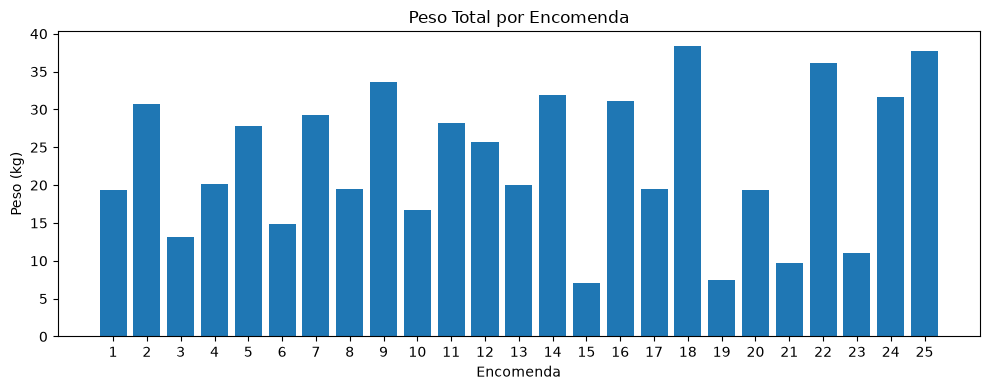

In [8]:
plt.figure(figsize=(10, 4))

plt.bar(
    pesos_encomendas.index.astype(str),
    pesos_encomendas.values
)

plt.title("Peso Total por Encomenda")
plt.xlabel("Encomenda")
plt.ylabel("Peso (kg)")
plt.tight_layout()
plt.show()



O dataset contém 580 kg de produtos distribuídos pelas 25 encomendas.

A encomenda mais pesada apresenta 38,4 kg, valor inferior à capacidade de ambos os veículos.

Apesar de nenhuma encomenda ultrapassar individualmente a capacidade disponível, será necessário controlar a carga acumulada ao longo de cada rota. Os veículos poderão realizar várias viagens durante o horizonte de planeamento.

## 5. Análise das Localizações

O problema utiliza diferentes pontos geográficos, correspondentes a produtores, ao centro de recolha e aos locais de entrega.

A análise das suas posições permite compreender a distribuição espacial das operações e preparar a construção das rotas.

location_type
delivery_location    7
producer             6
collection_center    1
Name: count, dtype: int64

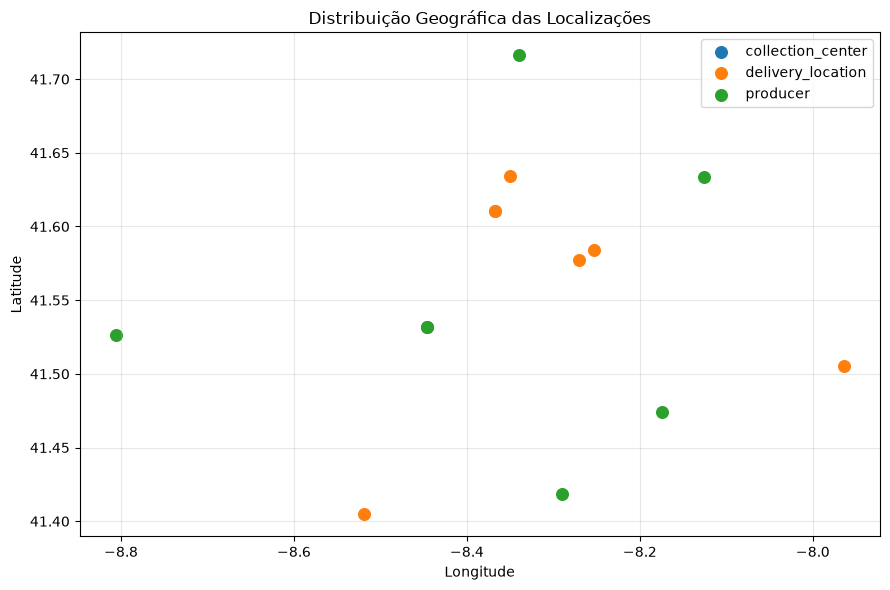

Localizações com coordenadas repetidas: 2


In [9]:
# Quantidade de pontos por tipo
display(locations["location_type"].value_counts())

# Representação geográfica
plt.figure(figsize=(9, 6))

for tipo, grupo in locations.groupby("location_type"):
    plt.scatter(
        grupo["longitude"],
        grupo["latitude"],
        label=tipo,
        s=70
    )

plt.title("Distribuição Geográfica das Localizações")
plt.xlabel("Longitude")
plt.ylabel("Latitude")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

print("Localizações com coordenadas repetidas:",
      locations.duplicated(
          subset=["latitude", "longitude"]
      ).sum())

## 6. Validação da Matriz de Distâncias

A matriz contém as distâncias e os tempos de viagem entre os pontos de routing.

Nesta secção é verificado se todos os pares origem-destino estão representados, se existem duplicados ou valores negativos e se a matriz apresenta simetria.

Esta informação será utilizada posteriormente para calcular os custos e tempos das rotas.

In [10]:
# Pares esperados
ids = set(locations["location_id"])

pares_esperados = {
    (a, b) for a in ids for b in ids if a != b
}

pares_existentes = set(zip(
    distance_matrix["origin_location_id"],
    distance_matrix["destination_location_id"]
))

# Verificar duplicados e valores negativos
duplicados = distance_matrix.duplicated(
    ["origin_location_id", "destination_location_id"]
).sum()

negativos = (
    (distance_matrix["distance_km"] < 0) |
    (distance_matrix["duration_min"] < 0)
).sum()

# Verificar simetria
inversa = distance_matrix[
    ["origin_location_id", "destination_location_id",
     "distance_km", "duration_min"]
].rename(columns={
    "origin_location_id": "destination_location_id",
    "destination_location_id": "origin_location_id",
    "distance_km": "dist_volta",
    "duration_min": "tempo_volta"
})

comparacao = distance_matrix.merge(
    inversa,
    on=["origin_location_id", "destination_location_id"],
    how="left"
)

assimetrias = (
    (~np.isclose(comparacao["distance_km"],
                 comparacao["dist_volta"])) |
    (~np.isclose(comparacao["duration_min"],
                 comparacao["tempo_volta"]))
).sum()

print("Pares esperados:", len(pares_esperados))
print("Pares existentes:", len(pares_existentes))
print("Pares em falta:", len(pares_esperados - pares_existentes))
print("Pares inesperados:", len(pares_existentes - pares_esperados))
print("Pares duplicados:", duplicados)
print("Valores negativos:", negativos)
print("Pares assimétricos:", assimetrias)

display(distance_matrix[
    ["distance_km", "duration_min"]
].describe().round(2))

Pares esperados: 182
Pares existentes: 182
Pares em falta: 0
Pares inesperados: 0
Pares duplicados: 0
Valores negativos: 0
Pares assimétricos: 0


,distance_km,duration_min
count,182.00,182.00
mean,30.45,40.59
std,17.14,22.85
min,0.00,0.00
25%,18.11,24.12
50%,28.69,38.30
75%,38.82,51.72
max,91.13,121.50




A matriz contém os 182 pares origem-destino esperados para as 14 localizações, não incluindo deslocações de um ponto para si próprio.

Não foram identificados pares duplicados, valores negativos ou diferenças entre os dois sentidos de deslocação.

Existem distâncias iguais a zero entre alguns pontos distintos que partilham as mesmas coordenadas geográficas.

A matriz apresenta, assim, a estrutura necessária para apoiar o cálculo das distâncias e dos tempos de viagem utilizados pelos algoritmos.

## 7. Conclusão

A análise exploratória permitiu compreender a estrutura e as principais características do dataset, constituído por 6 produtores, 21 clientes, 25 encomendas, 80 itens de encomenda e 2 veículos.

As verificações realizadas não identificaram valores em falta, registos duplicados, referências inválidas ou janelas temporais inconsistentes. A matriz de distâncias apresenta os 182 pares origem-destino esperados, sem valores negativos ou assimetrias.

Relativamente à capacidade de transporte, o peso total dos itens é de 580 kg, enquanto os veículos apresentam capacidades de 250 kg e 300 kg. Apesar de todas as encomendas caberem individualmente em qualquer um dos veículos, será necessário controlar a carga acumulada durante as rotas.

A análise temporal identificou 20 itens cujas janelas de recolha e entrega começam em dias diferentes. Este aspeto, juntamente com a passagem obrigatória pelo armazém e o limite de permanência de 24 horas, deverá ser considerado durante o planeamento.

Conclui-se que os dados apresentam uma estrutura consistente para avançar para a modelação do problema. 